=== Аналіз вибірки ===
Тренувальна: 15 об'єктів. Тестова: 5 об'єктів.
Розподіл класів у Train: 
target
0    0.6
1    0.4
Name: proportion, dtype: float64

Baseline Train F1: 0.375
Baseline CV F1   : 0.375
Unlimited Tree Train F1: 1.000
Unlimited Tree CV F1   : 1.000


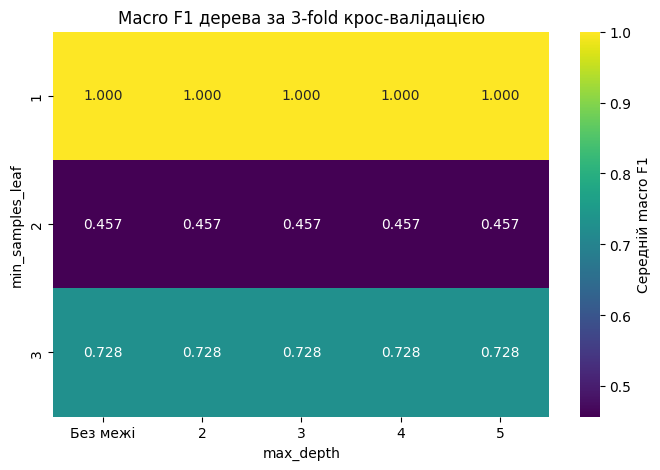


Найкращі параметри дерева: {'clf__max_depth': 2, 'clf__min_samples_leaf': 1}
Контрольоване дерево CV F1: 1.000


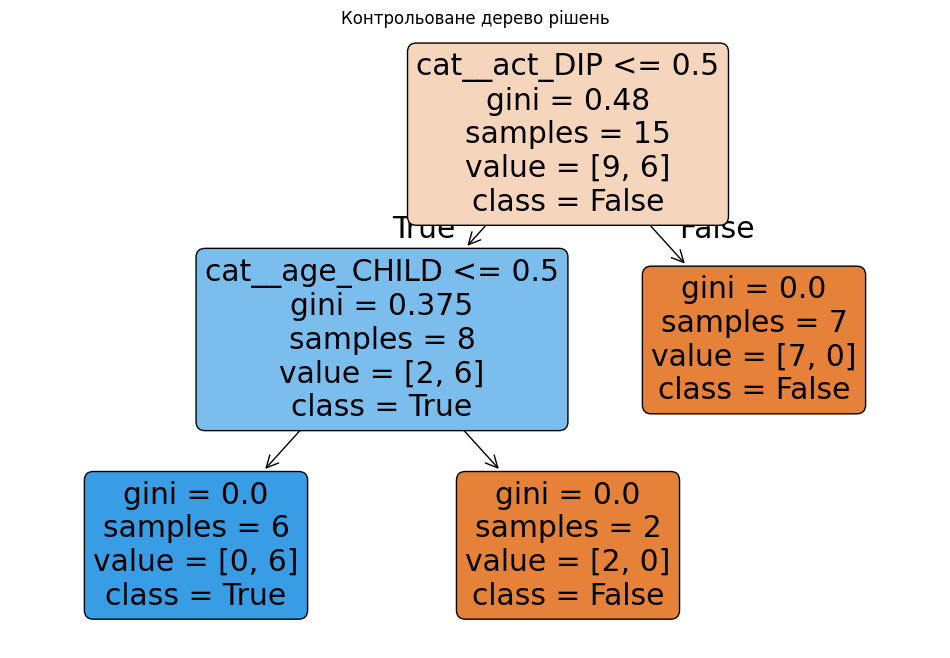

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# === 2. Підготовка даних ===
columns = ['color', 'size', 'act', 'age', 'inflated']
df = pd.read_csv(r"C:\Users\UserComp\Downloads\balloons\adult+stretch.data", names=columns)

df['target'] = df['inflated'].map({'T': 1, 'F': 0})
X = df.drop(columns=['inflated', 'target'])
y = df['target']

# Фіксований Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

print("=== Аналіз вибірки ===")
print(f"Тренувальна: {X_train.shape[0]} об'єктів. Тестова: {X_test.shape[0]} об'єктів.")
print(f"Розподіл класів у Train: \n{y_train.value_counts(normalize=True)}")

# Pipeline препроцесингу
cat_features = ['color', 'size', 'act', 'age']
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

def create_pipeline(model):
    return Pipeline([('prep', preprocessor), ('clf', model)])

cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# === 3. Baseline та Окреме дерево ===
# Baseline
baseline = create_pipeline(DummyClassifier(strategy='most_frequent'))
cv_base = cross_validate(baseline, X_train, y_train, cv=cv_strategy, scoring='f1_macro', return_train_score=True)
print(f"\nBaseline Train F1: {cv_base['train_score'].mean():.3f}")
print(f"Baseline CV F1   : {cv_base['test_score'].mean():.3f}")

# Необмежене дерево
tree_unlimited = create_pipeline(DecisionTreeClassifier(random_state=42))
cv_unlim = cross_validate(tree_unlimited, X_train, y_train, cv=cv_strategy, scoring='f1_macro', return_train_score=True)
print(f"Unlimited Tree Train F1: {cv_unlim['train_score'].mean():.3f}")
print(f"Unlimited Tree CV F1   : {cv_unlim['test_score'].mean():.3f}")

# Пошук структури контрольованого дерева
param_grid = {
    'clf__max_depth': [2, 3, 4, 5, None],
    'clf__min_samples_leaf': [1, 2, 3]
}

grid_tree = GridSearchCV(
    create_pipeline(DecisionTreeClassifier(random_state=42)),
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv_strategy,
    return_train_score=True,
    n_jobs=-1
)
grid_tree.fit(X_train, y_train)

# Візуалізація результатів сітки
results_df = pd.DataFrame(grid_tree.cv_results_)
pivot_table = results_df.pivot(index='param_clf__min_samples_leaf', columns='param_clf__max_depth', values='mean_test_score')
pivot_table.columns = [str(c) if c is not np.nan else 'Без межі' for c in pivot_table.columns]

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_table, annot=True, fmt=".3f", cmap="viridis", cbar_kws={'label': 'Середній macro F1'})
plt.title("Macro F1 дерева за 3-fold крос-валідацією")
plt.xlabel("max_depth")
plt.ylabel("min_samples_leaf")
plt.show()

best_tree_pipe = grid_tree.best_estimator_
print(f"\nНайкращі параметри дерева: {grid_tree.best_params_}")
print(f"Контрольоване дерево CV F1: {grid_tree.best_score_:.3f}")

# Візуалізація найкращого дерева
plt.figure(figsize=(12, 8))
# Отримуємо імена ознак після OneHotEncoder
feature_names = best_tree_pipe.named_steps['prep'].get_feature_names_out()
plot_tree(best_tree_pipe.named_steps['clf'], feature_names=feature_names, class_names=['False', 'True'], filled=True, rounded=True)
plt.title("Контрольоване дерево рішень")
plt.show()




=== Оцінка якості моделей (3-fold CV) ===


,Модель,Train F1,CV F1,CV Std,Мін. CV F1,Розрив (Train-CV)
0,Baseline,0.375,0.3750,0.0000,0.375,0.0000
1,Необмежене дерево,1.000,1.0000,0.0000,1.000,0.0000
2,Контрольоване дерево,1.000,1.0000,0.0000,1.000,0.0000
3,Випадковий ліс,1.000,0.8667,0.0943,0.800,0.1333
4,Градієнтний boosting,1.000,1.0000,0.0000,1.000,0.0000


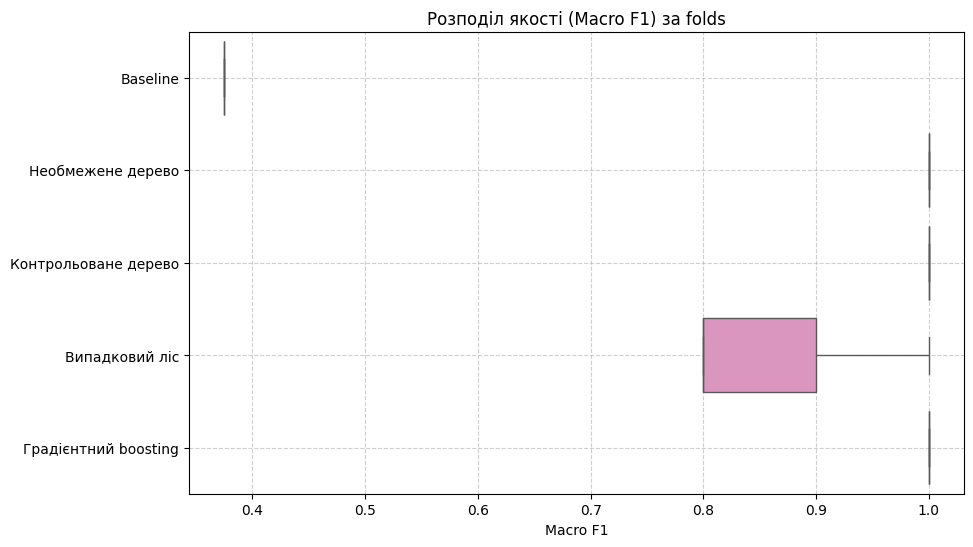

In [2]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import matplotlib.pyplot as plt
import seaborn as sns

# === 4. Ансамблеві моделі ===
rf_model = create_pipeline(RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42))
gb_model = create_pipeline(GradientBoostingClassifier(n_estimators=50, max_depth=2, learning_rate=0.1, random_state=42))

models = {
    "Baseline": baseline,
    "Необмежене дерево": tree_unlimited,
    "Контрольоване дерево": best_tree_pipe,
    "Випадковий ліс": rf_model,
    "Градієнтний boosting": gb_model
}

# === 5. Порівняння якості ===
records = []
fold_results = {}

print("=== Оцінка якості моделей (3-fold CV) ===")
for name, model in models.items():
    cv_res = cross_validate(model, X_train, y_train, cv=cv_strategy, scoring='f1_macro', return_train_score=True)
    
    # Зберігаємо результати по фолдах для графіка
    fold_results[name] = cv_res['test_score']
    
    records.append({
        "Модель": name,
        "Train F1": cv_res['train_score'].mean(),
        "CV F1": cv_res['test_score'].mean(),
        "CV Std": cv_res['test_score'].std(),
        "Мін. CV F1": cv_res['test_score'].min(),
        "Розрив (Train-CV)": cv_res['train_score'].mean() - cv_res['test_score'].mean()
    })

df_quality = pd.DataFrame(records)
display(df_quality.round(4))

# Побудова графіка розподілу fold-оцінок
plt.figure(figsize=(10, 6))
sns.boxplot(data=pd.DataFrame(fold_results), orient="h", palette="Set2")
plt.title("Розподіл якості (Macro F1) за folds")
plt.xlabel("Macro F1")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

=== Оцінка стійкості (10 повторів CV) ===


,Модель,mean,std,min,max
0,Випадковий ліс,0.9090,0.0878,0.6952,1.0
1,Градієнтний boosting,0.9861,0.0439,0.8611,1.0
2,Контрольоване дерево,0.9861,0.0439,0.8611,1.0


,Модель,Нестійкі об'єкти (>25% розбіжностей),Загальна розбіжність прогнозів (%)
0,Контрольоване дерево,0,1.33
1,Випадковий ліс,2,6.00
2,Градієнтний boosting,0,1.33


C:\Users\UserComp\AppData\Local\Temp\ipykernel_6824\497910436.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_roots['Частота'], y=df_roots.index, palette="viridis")


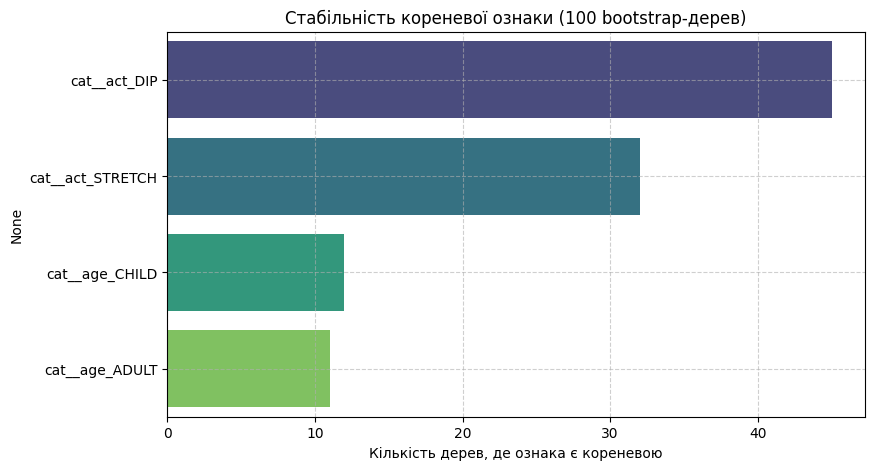


=== Частота кореневих ознак ===


,Частота
cat__act_DIP,45
cat__act_STRETCH,32
cat__age_CHILD,12
cat__age_ADULT,11


In [4]:
from sklearn.utils import resample
from sklearn.model_selection import cross_val_predict
import collections
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier

# === 6. Стійкість як властивість ML-рішення ===
n_repeats = 10
stability_records = []
oof_predictions = {name: np.zeros((len(X_train), n_repeats)) for name in ["Контрольоване дерево", "Випадковий ліс", "Градієнтний boosting"]}

print(f"=== Оцінка стійкості (10 повторів CV) ===")
for seed in range(n_repeats):
    cv_kfold = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    
    for name in ["Контрольоване дерево", "Випадковий ліс", "Градієнтний boosting"]:
        model = models[name]
        
        # Оцінка метрик
        scores = cross_validate(model, X_train, y_train, cv=cv_kfold, scoring='f1_macro')['test_score']
        
        # Отримання OOF прогнозів
        oof_preds = cross_val_predict(model, X_train, y_train, cv=cv_kfold, n_jobs=-1)
        oof_predictions[name][:, seed] = oof_preds
        
        stability_records.append({
            "Модель": name,
            "Seed": seed,
            "F1": scores.mean()
        })

df_stab = pd.DataFrame(stability_records)
summary_stab = df_stab.groupby("Модель")["F1"].agg(['mean', 'std', 'min', 'max']).reset_index()
display(summary_stab.round(4))

# Аналіз OOF-консенсусу
consensus_records = []
for name in ["Контрольоване дерево", "Випадковий ліс", "Градієнтний boosting"]:
    preds_matrix = oof_predictions[name]
    
    unstable_count = 0
    total_disagreements = 0
    
    for i in range(len(X_train)):
        obj_preds = preds_matrix[i, :]
        consensus_class = collections.Counter(obj_preds).most_common(1)[0][0]
        disagreements = np.sum(obj_preds != consensus_class)
        total_disagreements += disagreements
        
        if disagreements / n_repeats > 0.25:
            unstable_count += 1
            
    consensus_records.append({
        "Модель": name,
        "Нестійкі об'єкти (>25% розбіжностей)": unstable_count,
        "Загальна розбіжність прогнозів (%)": (total_disagreements / (len(X_train) * n_repeats)) * 100
    })

display(pd.DataFrame(consensus_records).round(2))

# === 7. Стійкість структури дерева ===
n_bootstrap = 100
root_features = []

# Отримуємо назви ознак після OHE
feature_names = best_tree_pipe.named_steps['prep'].get_feature_names_out()

for i in range(n_bootstrap):
    X_b, y_b = resample(X_train, y_train, random_state=i)
    
    # Клонуємо і навчаємо пайплайн
    boot_tree = create_pipeline(DecisionTreeClassifier(max_depth=2, min_samples_leaf=1, random_state=i))
    boot_tree.fit(X_b, y_b)
    
    tree_struct = boot_tree.named_steps['clf'].tree_
    # Індекс ознаки в корені (вузол 0)
    root_feat_idx = tree_struct.feature[0]
    
    if root_feat_idx != -2: # -2 означає що це листок (якщо дерево не поділилося)
        root_features.append(feature_names[root_feat_idx])
    else:
        root_features.append("Не поділилося (Листок)")

root_counts = collections.Counter(root_features)
df_roots = pd.DataFrame.from_dict(root_counts, orient='index', columns=['Частота']).sort_values(by='Частота', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(x=df_roots['Частота'], y=df_roots.index, palette="viridis")
plt.title("Стабільність кореневої ознаки (100 bootstrap-дерев)")
plt.xlabel("Кількість дерев, де ознака є кореневою")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("\n=== Частота кореневих ознак ===")
display(df_roots)

=== Важливість ознак ===


,Ознака,Tree Impurity,RF Impurity,RF Mean Permutation,RF Permutation Std
5,cat__act_STRETCH,0.0000,0.2744,0.1324,0.1159
4,cat__act_DIP,0.5833,0.2345,0.1070,0.0831
7,cat__age_CHILD,0.4167,0.2298,0.0895,0.0356
6,cat__age_ADULT,0.0000,0.1239,0.0513,0.0565
1,cat__color_YELLOW,0.0000,0.0430,0.0000,0.0000
2,cat__size_LARGE,0.0000,0.0368,0.0000,0.0000
0,cat__color_PURPLE,0.0000,0.0321,0.0000,0.0000
3,cat__size_SMALL,0.0000,0.0256,-0.0200,0.0283


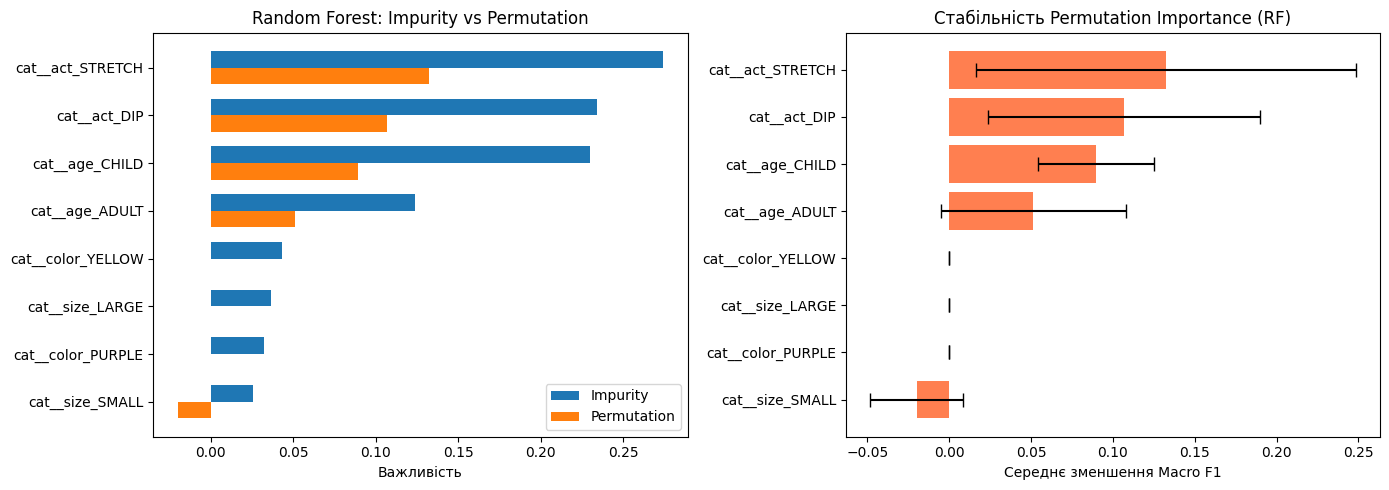

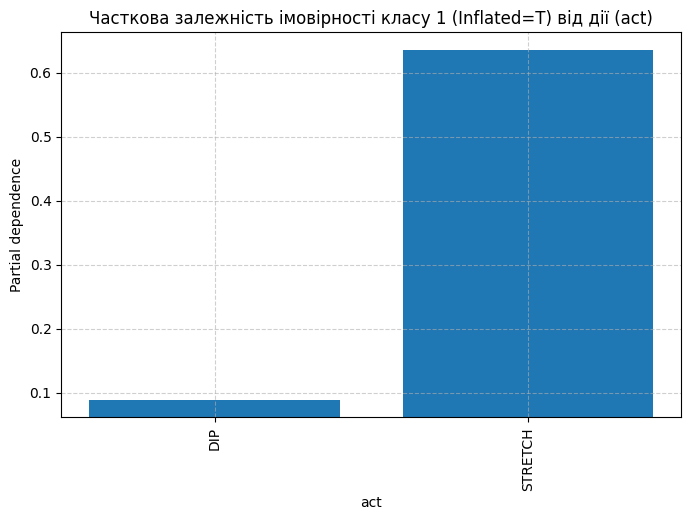

In [5]:
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# === 8. Важливість ознак та її варіативність ===
# Навчаємо моделі на всьому X_train для отримання Impurity
best_tree_pipe.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

feature_names = best_tree_pipe.named_steps['prep'].get_feature_names_out()

# Impurity importance
tree_impurity = best_tree_pipe.named_steps['clf'].feature_importances_
rf_impurity = rf_model.named_steps['clf'].feature_importances_

# Permutation importance (на валідаційних фолдах для RF)
perm_scores = {feat: [] for feat in feature_names}
cv_perm = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

for train_idx, valid_idx in cv_perm.split(X_train, y_train):
    X_f_train, X_f_valid = X_train.iloc[train_idx], X_train.iloc[valid_idx]
    y_f_train, y_f_valid = y_train.iloc[train_idx], y_train.iloc[valid_idx]
    
    # Клонуємо та навчаємо RF на фолді
    rf_fold = create_pipeline(RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42))
    rf_fold.fit(X_f_train, y_f_train)
    
    # Виконуємо пермутацію на трансформованих даних
    X_f_valid_trans = rf_fold.named_steps['prep'].transform(X_f_valid)
    
    # Обчислюємо permutation importance
    r = permutation_importance(
        rf_fold.named_steps['clf'], X_f_valid_trans, y_f_valid, 
        scoring='f1_macro', n_repeats=10, random_state=42
    )
    
    for i, feat in enumerate(feature_names):
        perm_scores[feat].append(r.importances_mean[i])

# Агрегуємо результати
importance_records = []
for i, feat in enumerate(feature_names):
    fold_importances = perm_scores[feat]
    mean_perm = np.mean(fold_importances)
    std_perm = np.std(fold_importances)
    
    importance_records.append({
        "Ознака": feat,
        "Tree Impurity": tree_impurity[i],
        "RF Impurity": rf_impurity[i],
        "RF Mean Permutation": mean_perm,
        "RF Permutation Std": std_perm
    })

df_importance = pd.DataFrame(importance_records).sort_values(by="RF Mean Permutation", ascending=False)
print("=== Важливість ознак ===")
display(df_importance.round(4))

# Візуалізація важливості
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Impurity vs Permutation для RF
bar_width = 0.35
index = np.arange(len(df_importance))

ax[0].barh(index, df_importance['RF Impurity'], bar_width, label='Impurity')
ax[0].barh(index + bar_width, df_importance['RF Mean Permutation'], bar_width, label='Permutation')
ax[0].set_yticks(index + bar_width / 2)
ax[0].set_yticklabels(df_importance['Ознака'])
ax[0].invert_yaxis()
ax[0].set_xlabel('Важливість')
ax[0].set_title('Random Forest: Impurity vs Permutation')
ax[0].legend()

# Permutation Stability (з вусиками std)
ax[1].barh(index, df_importance['RF Mean Permutation'], xerr=df_importance['RF Permutation Std'], capsize=5, color='coral')
ax[1].set_yticks(index)
ax[1].set_yticklabels(df_importance['Ознака'])
ax[1].invert_yaxis()
ax[1].set_xlabel('Середнє зменшення Macro F1')
ax[1].set_title('Стабільність Permutation Importance (RF)')

plt.tight_layout()
plt.show()

# === 9. Partial Dependence Plot ===
# Будуємо для оригінальної ознаки 'act'
plt.figure(figsize=(8, 5))
PartialDependenceDisplay.from_estimator(
    rf_model, X_train, features=['act'], target=1, 
    categorical_features=['act'], ax=plt.gca()
)
plt.title("Часткова залежність імовірності класу 1 (Inflated=T) від дії (act)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [6]:
import time
import pickle
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

# === 10. Розбіжності прогнозів ===
# Отримуємо OOF-прогнози
oof_tree = cross_val_predict(best_tree_pipe, X_train, y_train, cv=cv_strategy)
oof_rf = cross_val_predict(rf_model, X_train, y_train, cv=cv_strategy)
oof_gb = cross_val_predict(gb_model, X_train, y_train, cv=cv_strategy)

df_oof = pd.DataFrame({
    'True_Label': y_train.values,
    'Tree_Pred': oof_tree,
    'RF_Pred': oof_rf,
    'GB_Pred': oof_gb
})

# Знаходимо розбіжності
disagreements = df_oof[(df_oof['Tree_Pred'] != df_oof['RF_Pred']) | (df_oof['Tree_Pred'] != df_oof['GB_Pred'])]
print(f"=== Аналіз розбіжностей OOF-прогнозів ===")
print(f"Знайдено об'єктів із розбіжностями: {len(disagreements)}")
if not disagreements.empty:
    display(disagreements)

# === 11. Інженерні характеристики ===
perf_records = []
for name, model in models.items():
    if name == "Baseline" or name == "Необмежене дерево":
        continue
        
    start_train = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start_train
    
    start_pred = time.perf_counter()
    model.predict(X_train)
    pred_time = time.perf_counter() - start_pred
    
    model_size_kb = len(pickle.dumps(model)) / 1024
    
    perf_records.append({
        "Модель": name,
        "Fit (с)": train_time,
        "Predict 15 об'єктів (мс)": pred_time * 1000,
        "Розмір (КБ)": model_size_kb
    })

df_perf = pd.DataFrame(perf_records)
print("\n=== Обчислювальні характеристики ===")
display(df_perf.round(4))

# === 12. Вибір моделі та фінальна перевірка на Test Set ===
# Навчаємо обрану модель (Контрольоване дерево) на всьому D_train
final_model = best_tree_pipe
final_model.fit(X_train, y_train)

# ОДНОРАЗОВЕ застосування до D_test
y_test_pred = final_model.predict(X_test)

test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average='macro')
conf_matrix = confusion_matrix(y_test, y_test_pred)

print("\n=== РЕЗУЛЬТАТИ НА TEST SET ===")
print(f"Обрана модель : Контрольоване дерево")
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Test Macro F1 : {test_f1:.4f}")
print("Матриця помилок:")
print(conf_matrix)
print("\nТестова вибірка не використовувалася на жодному етапі налаштувань.")

=== Аналіз розбіжностей OOF-прогнозів ===
Знайдено об'єктів із розбіжностями: 2


,True_Label,Tree_Pred,RF_Pred,GB_Pred
6,0,0,1,0
14,0,0,1,0



=== Обчислювальні характеристики ===


,Модель,Fit (с),Predict 15 об'єктів (мс),Розмір (КБ)
0,Контрольоване дерево,0.0667,29.8496,2.7051
1,Випадковий ліс,0.4901,37.0926,89.3174
2,Градієнтний boosting,0.1125,9.0899,39.0967



=== РЕЗУЛЬТАТИ НА TEST SET ===
Обрана модель : Контрольоване дерево
Test Accuracy : 1.0000
Test Macro F1 : 1.0000
Матриця помилок:
[[3 0]
 [0 2]]

Тестова вибірка не використовувалася на жодному етапі налаштувань.


# AI_USAGE.md

- **Яку задачу поставлено системі ШІ:** Написати код для аналізу важливості ознак (Feature Importance) та зробити висновок щодо головних факторів впливу на цільову змінну на основі окремого дерева рішень[cite: 57].
- **Що запропонувала система та які припущення зробила:** ШІ запропонував вивести атрибут `feature_importances_` (Impurity) і зробити висновок, що ознака з найвищим балом (`cat__act_DIP`) є найважливішою причиною. Припущення: impurity на тренувальних даних дорівнює об'єктивній узагальнювальній важливості, а взаємозамінністю ознак (кореляцією) можна знехтувати[cite: 56, 57].
- **Що студент прийняв, змінив або відхилив:** Програмний код отримання `feature_importances_` прийнято. Аналітичний висновок відхилено[cite: 56, 57]. Висновок змінено на обережніший: impurity показує лише локальну структуру навченого дерева, а не реальний закон даних[cite: 56].
- **Яким запуском, тестом або порівнянням перевірено результат:** Проведено порівняння Impurity importance з Permutation importance на валідаційних частинах 3-fold крос-валідації (з розрахунком стандартного відхилення). Також виконано аналіз 100 bootstrap-вибірок для перевірки стабільності кореневої ознаки[cite: 56, 57].
- **Де містяться машинозчитувані докази:** Докази збережено у виведених таблицях `df_importance` (порівняння методів важливості) та `df_roots` (частота появи ознак у кореневому вузлі), а також на відповідних графіках у Jupyter Notebook[cite: 57].